Features shape: (442, 10)
Target shape: (442,)

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
Missing values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64
X shape: 

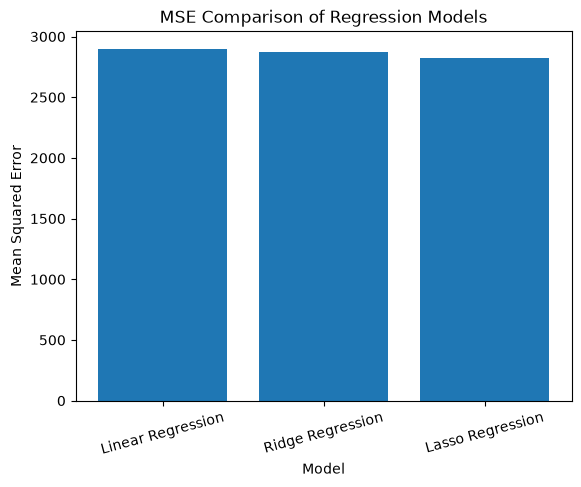

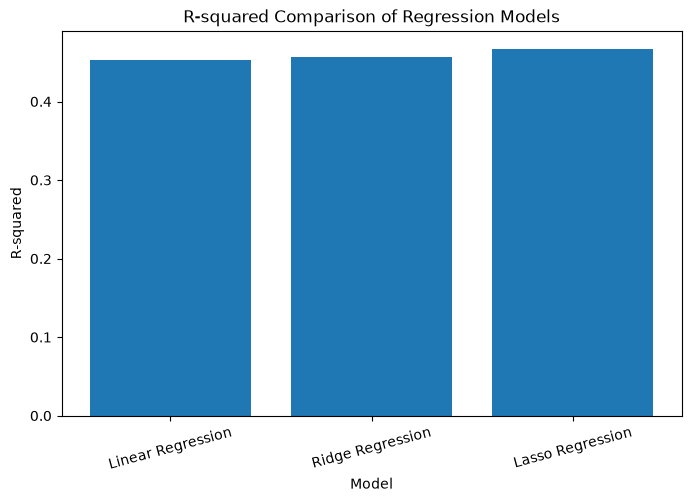

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score


diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature names:")
print(diabetes.feature_names)

df = pd.DataFrame(X, columns=diabetes.feature_names)
df['target'] = y
print(df.head())

print("Missing values:")
print(df.isnull().sum())

X = df.drop('target', axis=1)
y = df['target']
print("X shape:", X.shape)
print("y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------")
print("MSE:", linear_mse)
print("R2:", linear_r2)


ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])
ridge_params = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100]
}
ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring='neg_mean_squared_error'
)
ridge_grid.fit(X_train, y_train)
print("Best Ridge alpha:", ridge_grid.best_params_['ridge__alpha'])

best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test)
ridge_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("-----------------")
print("MSE:", ridge_mse)
print("R2:", ridge_r2)


lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(max_iter=10000))
])
lasso_params = {
    'lasso__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}
lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring='neg_mean_squared_error'
)
lasso_grid.fit(X_train, y_train)
print("Best Lasso alpha:", lasso_grid.best_params_['lasso__alpha'])

best_lasso = lasso_grid.best_estimator_
y_pred_lasso = best_lasso.predict(X_test)
lasso_mse = mean_squared_error(y_test, y_pred_lasso)
lasso_r2 = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("-----------------")
print("MSE:", lasso_mse)
print("R2:", lasso_r2)


results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],
    'MSE': [
        linear_mse,
        ridge_mse,
        lasso_mse
    ],
    'R-squared': [
        linear_r2,
        ridge_r2,
        lasso_r2
    ]
})
print(results)

best_model = results.loc[results['MSE'].idxmin(), 'Model']
print("Best model based on MSE:", best_model)


plt.bar(results['Model'], results['MSE'])
plt.xlabel('Model')
plt.ylabel('Mean Squared Error')
plt.title('MSE Comparison of Regression Models')
plt.xticks(rotation=15)
plt.show()


plt.figure(figsize=(8, 5))
plt.bar(results['Model'], results['R-squared'])
plt.xlabel('Model')
plt.ylabel('R-squared')
plt.title('R-squared Comparison of Regression Models')
plt.xticks(rotation=15)
plt.show()